## Этап 3, часть 2. Предобработка данных матчей CS2 на FACEIT

Кукин Олег АД-24

[Датасет на Kaggle](https://www.kaggle.com/datasets/piercehentosh/counter-strike-2-win-prediction-faceit)

## 1 Загрузка данных

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

In [ ]:
df = pd.read_csv("win_prediction_data_clean1.csv", sep=";")

## 2 Проверка и очистка данных

In [ ]:
df.isna().sum()

win                          0
map                          0
Team_A_avg_win_percentage    0
Team_A_avg_KR                0
Team_A_avg_elo               0
Team_B_avg_win_percentage    0
Team_B_avg_KR                0
Team_B_avg_elo               0
Match ID                     0
dtype: int64

In [ ]:
print("Полных дубликатов:", df.duplicated().sum())
print("Повторных записей по ID сверх первой:", df["Match ID"].duplicated().sum())

Полных дубликатов: 0
Повторных записей по ID сверх первой: 534


In [ ]:
print("Процент побед A вне 0-100:", ((df["Team_A_avg_win_percentage"] < 0) | (df["Team_A_avg_win_percentage"] > 100)).sum())
print("Процент побед B вне 0-100:", ((df["Team_B_avg_win_percentage"] < 0) | (df["Team_B_avg_win_percentage"] > 100)).sum())
print("K/R A ниже нуля:", (df["Team_A_avg_KR"] < 0).sum())
print("K/R B ниже нуля:", (df["Team_B_avg_KR"] < 0).sum())
print("ELO A не больше нуля:", (df["Team_A_avg_elo"] <= 0).sum())
print("ELO B не больше нуля:", (df["Team_B_avg_elo"] <= 0).sum())

Процент побед A вне 0-100: 0
Процент побед B вне 0-100: 0
K/R A ниже нуля: 0
K/R B ниже нуля: 0
ELO A не больше нуля: 0
ELO B не больше нуля: 0


In [ ]:
df["win"].unique()

array(['team a', 'team b'], dtype=object)

In [ ]:
map_counts = df.groupby("Match ID")["map"].nunique()
win_counts = df.groupby("Match ID")["win"].nunique()
print("ID с разными картами:", (map_counts > 1).sum())
print("ID с разными победителями:", (win_counts > 1).sum())

ID с разными картами: 0
ID с разными победителями: 0


In [ ]:
df = df.drop_duplicates(subset="Match ID", keep="first").copy()
print("Матчей после очистки:", len(df))
print("Повторов ID после очистки:", df["Match ID"].duplicated().sum())

Матчей после очистки: 9117
Повторов ID после очистки: 0


## 3 Разделение на train и test: 80/20

### Победу A это 1, победа B это 0.

In [ ]:
X = df.drop(columns=["win", "Match ID"])
y = df["win"].map({"team a": 1, "team b": 0})

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train:", len(X_train))
print("Test:", len(X_test))

Train: 7293
Test: 1824


## 4 Масштабирование ELO команды A

In [ ]:
elo = X_train[["Team_A_avg_elo"]]
comparison = elo.copy()
comparison.columns = ["Исходный ELO"]

In [ ]:
standard = StandardScaler()
comparison["StandardScaler"] = standard.fit_transform(elo)

In [ ]:
minmax = MinMaxScaler()
comparison["MinMaxScaler"] = minmax.fit_transform(elo)

In [ ]:
robust = RobustScaler()
comparison["RobustScaler"] = robust.fit_transform(elo)

In [ ]:
comparison.describe().round(3)

,Исходный ELO,StandardScaler,MinMaxScaler,RobustScaler
count,7293.000,7293.000,7293.000,7293.000
mean,1754.907,0.000,0.310,0.106
std,414.563,1.000,0.140,0.748
min,836.000,-2.217,0.000,-1.552
25%,1453.000,-0.728,0.208,-0.439
50%,1696.200,-0.142,0.290,0.000
75%,2007.200,0.609,0.395,0.561
max,3803.800,4.943,1.000,3.803


## 5 Графики до и после масштабирования

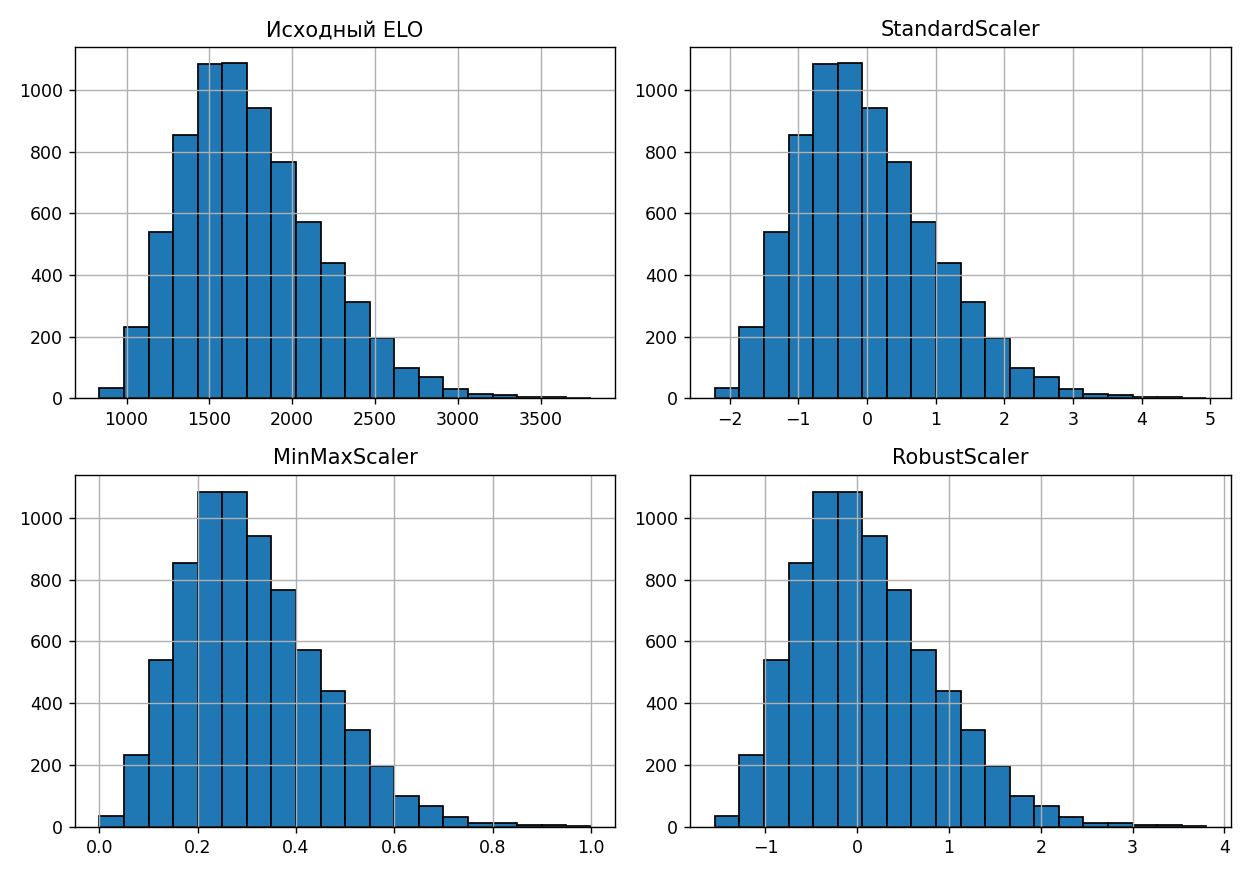

In [ ]:
comparison.hist(bins=20, figsize=(10, 7), edgecolor="black")
plt.tight_layout()
plt.show()

Форма распределения сохранилась. StandardScaler: среднее 0, стандартное отклонение примерно 1. MinMaxScaler: значения train от 0 до 1. RobustScaler: медиана 0, масштаб по межквартильному размаху.

Выбираю RobustScaler: он меньше зависит от крайних значений ELO.

## 6 Масштабирование числовых признаков

In [ ]:
numeric_columns = [
    "Team_A_avg_win_percentage", "Team_A_avg_KR", "Team_A_avg_elo",
    "Team_B_avg_win_percentage", "Team_B_avg_KR", "Team_B_avg_elo"
]

In [ ]:
scaler = RobustScaler()
X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])

## 7 Кодирование карт

In [ ]:
X_train = pd.get_dummies(X_train, columns=["map"], dtype=int)
X_test = pd.get_dummies(X_test, columns=["map"], dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

## 8 Проверка результата

In [ ]:
X_train.head()

,Team_A_avg_win_percentage,Team_A_avg_KR,Team_A_avg_elo,Team_B_avg_win_percentage,Team_B_avg_KR,Team_B_avg_elo,map_de_ancient,map_de_anubis,map_de_dust2,map_de_inferno,map_de_mirage,map_de_nuke,map_de_overpass,map_de_train,map_de_vertigo
9107,-3.253369,-1.221107,-0.573439,-0.770527,-0.001525,-0.866366,0,0,0,0,0,0,0,0,1
8860,0.148480,1.226865,-0.448935,-2.075688,-2.175524,-0.006006,0,0,0,0,0,0,1,0,0
2478,0.039255,0.261544,-0.307470,0.667623,0.953978,-0.472973,0,0,0,0,1,0,0,0,0
4716,-3.973295,-4.101654,0.167088,-1.949820,-2.340119,-0.009009,0,0,0,0,0,0,0,0,1
1644,-1.610065,-1.229568,0.434500,-0.106461,-0.662497,1.298799,1,0,0,0,0,0,0,0,0


In [ ]:
print("Размер train:", X_train.shape)
print("Размер test:", X_test.shape)
print("Пропуски train:", X_train.isna().sum().sum())
print("Пропуски test:", X_test.isna().sum().sum())
print("Одинаковые столбцы:", X_train.columns.equals(X_test.columns))

Размер train: (7293, 15)
Размер test: (1824, 15)
Пропуски train: 0
Пропуски test: 0
Одинаковые столбцы: True


## 9 Вывод

### Для дальнейшего обучения подготовлены 7293 матча в train и 1824 в test: 6 числовых признаков и 9 столбцов карт. Пропусков нет, наборы столбцов совпадают. Параметры масштабирования рассчитаны только на train.